# Parte 0 — O piso

**Objetivo:** estabelecer um piso experimental treinando apenas com `rotulos_5.csv` (105 imagens) e comparar **(a) uma CNN pequena treinada do zero** com **(b) uma ResNet-18 pré-treinada no ImageNet com fine-tuning**. Os conjuntos de validação e `test_public` são usados para seleção de checkpoint e avaliação, respectivamente, não para treinamento.

In [1]:
from torch.utils.data import DataLoader
import pandas as pd
%load_ext autoreload
%autoreload 2
from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay
import torch
import torch.nn as nn
import numpy as np
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
# Importando a classe do seu arquivo dentro de src
from src.redimensionamento import DatasetTrap, train_epoch, transform_treino, transform_val, eval_model, CNN_pequena
from src.autosup import criar_classificador
from sklearn.metrics import classification_report
import seaborn as sns

## Reprodutibilidade

In [9]:
import random
torch.manual_seed(0); np.random.seed(0); random.seed(0)


## Dados

Leitura dos rótulos de treino, validação e teste público; codificação consistente das classes com `LabelEncoder` ajustado somente no treino.

In [10]:
df_treino = pd.read_csv("pa3_dados/labels/rotulos_5.csv")
df_val = pd.read_csv("pa3_dados/labels/val.csv")
df_teste = pd.read_csv('pa3_dados/labels/test_public.csv')
le = LabelEncoder()
df_treino['label'] = le.fit_transform(df_treino['label'])
df_val['label'] = le.transform(df_val['label'])
df_teste['label'] = le.transform(df_teste['label'])



In [11]:
dataset_treino = DatasetTrap(df=df_treino, raiz="pa3_dados/images/train", augment=transform_treino)
dataset_val = DatasetTrap(df=df_val, raiz="pa3_dados/images/val", augment=transform_val)
dataset_teste = DatasetTrap(df=df_teste, raiz = "pa3_dados/images/test_public", augment= transform_val  )

loader_val = DataLoader(dataset_val, batch_size=16, shuffle= False)
loader_train = DataLoader(dataset_treino, batch_size=16, shuffle= True)
loader_test = DataLoader(dataset_teste, batch_size= 16, shuffle= False)

In [12]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'xpu' if hasattr(torch, 'xpu') and torch.xpu.is_available() else 'cpu')
print(DEVICE)

cpu


In [13]:
# Pesos de classe calculados somente a partir dos 105 exemplos de treino
rotulos_treino = df_treino['label'].values
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(rotulos_treino),
    y=rotulos_treino,
)
pesos_tensor = torch.tensor(pesos, dtype=torch.float32, device=DEVICE)

## (b) ResNet-18 pré-treinada com fine-tuning

In [14]:
modelo = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
num_entradas = modelo.fc.in_features
modelo.fc = nn.Linear(num_entradas, len(le.classes_))
modelo = modelo.to(DEVICE)
criterio = nn.CrossEntropyLoss(weight=pesos_tensor)

In [15]:
history = train_epoch(model=modelo, device=DEVICE, criterio=criterio, train_loader=loader_train, val_loader=loader_val, label="resnet18_parte0")

Epoch 1/10 | F1: 0.1008 | Train Loss: 3.062347121465774 | Val Loss: 2.8588404891514543 
Epoch 2/10 | F1: 0.2052 | Train Loss: 2.1308730352492558 | Val Loss: 2.5940409745320236 
Epoch 3/10 | F1: 0.2915 | Train Loss: 1.6173546200706845 | Val Loss: 2.4078286048209314 
Epoch 4/10 | F1: 0.3320 | Train Loss: 1.168912106468564 | Val Loss: 2.2763480007058323 
Epoch 5/10 | F1: 0.3706 | Train Loss: 0.8698496500651042 | Val Loss: 2.197902263981281 
Epoch 6/10 | F1: 0.3856 | Train Loss: 0.7219132196335566 | Val Loss: 2.1460589418316833 
Epoch 7/10 | F1: 0.3834 | Train Loss: 0.5320655459449405 | Val Loss: 2.084296802482983 
Epoch 8/10 | F1: 0.3940 | Train Loss: 0.4110186985560826 | Val Loss: 2.036668078734143 
Epoch 9/10 | F1: 0.4236 | Train Loss: 0.28881407238188245 | Val Loss: 2.0282405437809405 
Epoch 10/10 | F1: 0.4426 | Train Loss: 0.2585827418736049 | Val Loss: 2.0404172085299352 


### Curva de treino e validação

A partir das curvas, observa-se indício de **sobreajuste por volta da época 7**, quando o modelo começa a decorar os exemplos de treino. A escolha do checkpoint é feita pela melhor F1 macro de validação, não pela última época.

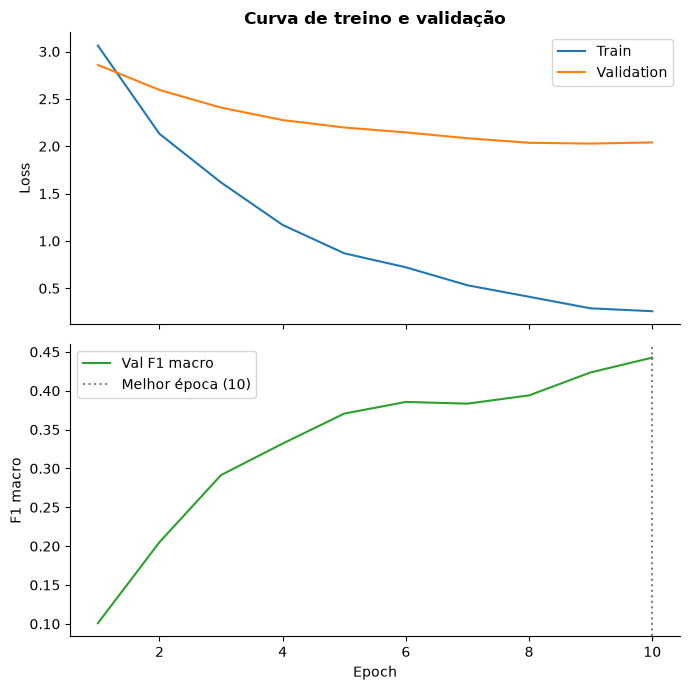

In [16]:
epocas = range(1, len(history['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)

# Loss
ax1.plot(epocas, history['train_loss'], label='Train')
ax1.plot(epocas, history['val_loss'], label='Validation')
ax1.set_ylabel('Loss')
ax1.set_title('Curva de treino e validação', fontweight='bold')
ax1.legend()

# F1 de validação
ax2.plot(epocas, history['f1_score'], color='tab:green', label='Val F1 macro')
melhor = int(np.argmax(history['f1_score']))
ax2.axvline(melhor + 1, color='gray', linestyle=':', label=f'Melhor época ({melhor + 1})')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('F1 macro')
ax2.legend()

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Avaliação no test_public (checkpoint de melhor F1 no val)

In [17]:
# Recupera o checkpoint escolhido pela melhor F1 macro na validação
pesos_salvos = torch.load('models/best_model_resnet18_parte0.pt', map_location=DEVICE, weights_only=True)
modelo.load_state_dict(pesos_salvos)
previsoes_teste, rotulos_teste = eval_model(modelo, loader_test, criterio, DEVICE)
print('F1 macro (b):', f1_score(rotulos_teste, previsoes_teste, average='macro'))
print('Acurácia (b):', accuracy_score(rotulos_teste, previsoes_teste))

 F1: 0.4524 |  Teste Loss 1.9083682435361438 
F1 macro (b): 0.4524249286202189
Acurácia (b): 0.468557336621455


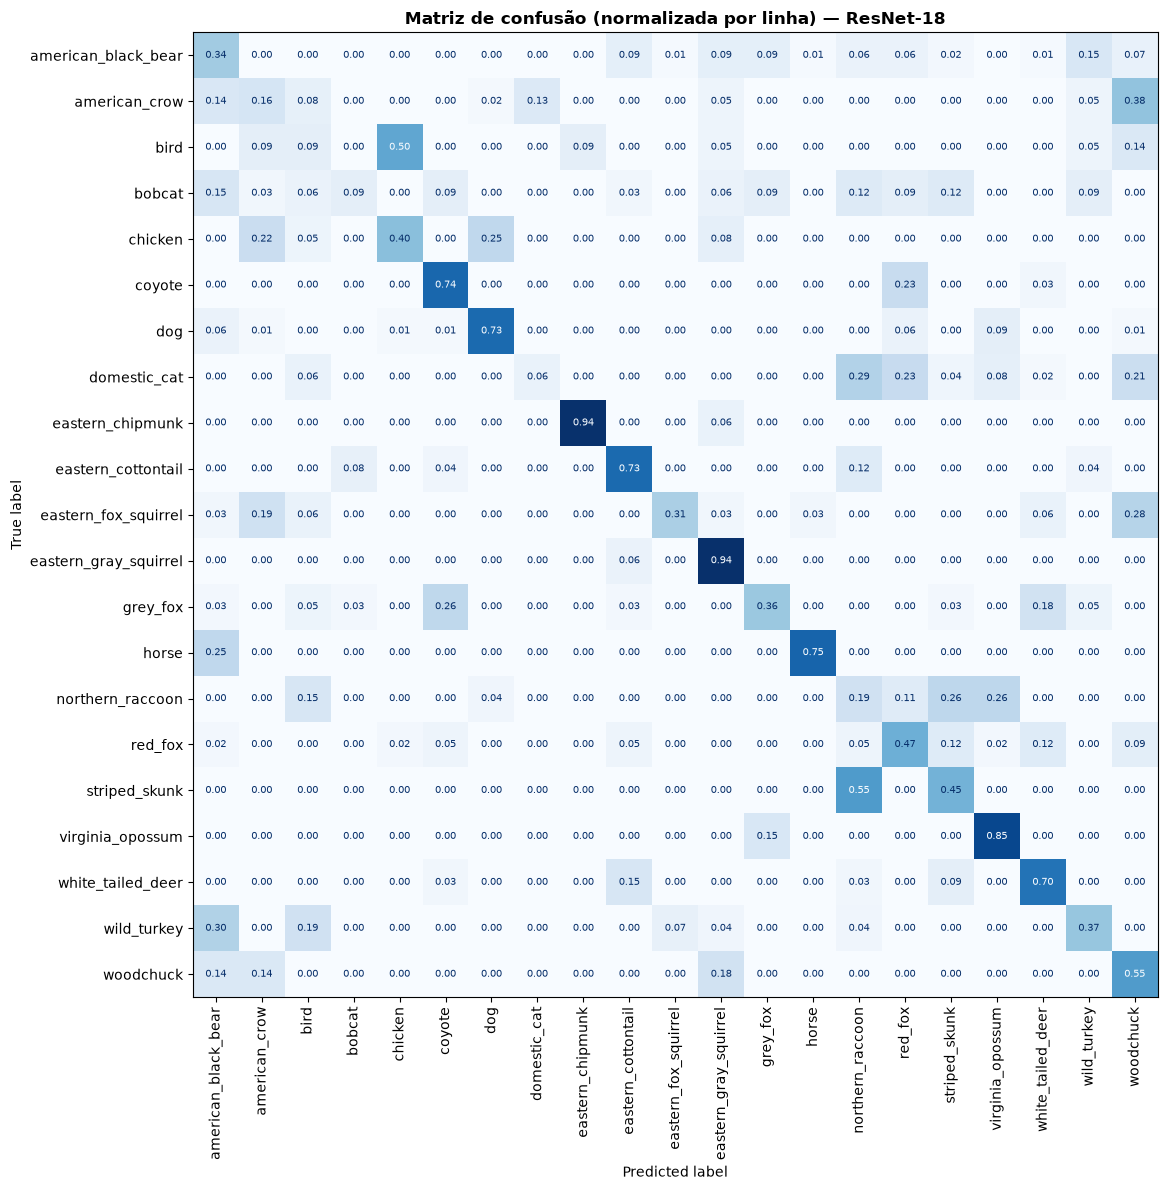

In [18]:
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    rotulos_teste, previsoes_teste,
    labels=range(len(le.classes_)),
    display_labels=le.classes_,
    normalize='true',
    values_format='.2f',
    xticks_rotation=90,
    colorbar=False,
    cmap='Blues',
    ax=ax,
)
for t in ax.texts:
    t.set_fontsize(7)
ax.set_title('Matriz de confusão (normalizada por linha) — ResNet-18', fontweight='bold')
plt.tight_layout()
plt.show()

## (a) CNN pequena do zero

In [19]:
modelo_CNN = CNN_pequena().to(DEVICE)
criterio_cnn = nn.CrossEntropyLoss(weight=pesos_tensor)

history_opcao_a = train_epoch(
    model=modelo_CNN,
    device=DEVICE,
    criterio=criterio_cnn,
    train_loader=loader_train,
    val_loader=loader_val,
    label="cnn_parte0",
    epochs=60,      # suba para 100 se a val ainda estiver melhorando
    lr=1e-3,
)
modelo_CNN.load_state_dict(torch.load('models/best_model_cnn_parte0.pt', map_location=DEVICE, weights_only=True))


previsoes_a, rotulos_a = eval_model(modelo_CNN, loader_test, criterio_cnn, DEVICE)
print("F1 macro:", f1_score(rotulos_a, previsoes_a, average='macro'))
print("Acurácia:", accuracy_score(rotulos_a, previsoes_a))

Epoch 1/60 | F1: 0.0139 | Train Loss: 3.382073974609375 | Val Loss: 3.0429590810643563 
Epoch 2/60 | F1: 0.0687 | Train Loss: 3.018209693545387 | Val Loss: 2.983582147277228 
Epoch 3/60 | F1: 0.1018 | Train Loss: 2.7685395740327383 | Val Loss: 3.0290340008121905 
Epoch 4/60 | F1: 0.1453 | Train Loss: 2.4593837193080357 | Val Loss: 3.1177214065400682 
Epoch 5/60 | F1: 0.1258 | Train Loss: 2.1701956612723214 | Val Loss: 3.3497474594871597 
Epoch 6/60 | F1: 0.1633 | Train Loss: 1.8767145066034225 | Val Loss: 3.511894603767017 
Epoch 7/60 | F1: 0.1874 | Train Loss: 1.711516607375372 | Val Loss: 3.96715251053914 
Epoch 8/60 | F1: 0.1807 | Train Loss: 1.5922693161737351 | Val Loss: 4.062820887801671 
Epoch 9/60 | F1: 0.1544 | Train Loss: 1.4721384684244792 | Val Loss: 4.070594409904857 
Epoch 10/60 | F1: 0.1713 | Train Loss: 1.146810331798735 | Val Loss: 4.1260499859800435 
Epoch 11/60 | F1: 0.1953 | Train Loss: 1.0771558489118302 | Val Loss: 4.689191157274907 
Epoch 12/60 | F1: 0.1733 | Tra

## Resumo do piso

Comparação dos dois modelos no mesmo conjunto `test_public`, usando F1 macro e acurácia.

In [20]:
resumo = pd.DataFrame({
    'modelo': ['CNN do zero (a)', 'ResNet-18 ImageNet (b)'],
    'f1_macro': [f1_score(rotulos_a, previsoes_a, average='macro'),
                 f1_score(rotulos_teste, previsoes_teste, average='macro')],
    'acuracia': [accuracy_score(rotulos_a, previsoes_a),
                 accuracy_score(rotulos_teste, previsoes_teste)],
})
resumo

,modelo,f1_macro,acuracia
0,CNN do zero (a),0.299801,0.345253
1,ResNet-18 ImageNet (b),0.452425,0.468557


# Parte 1 — Trilha A: auto-supervisionado (SimCLR)

Continuamos o pré-treino do backbone (ResNet-18) com **SimCLR** sobre as 6.505 imagens do `train`, **sem usar nenhum rótulo** (só os ids dos arquivos). Depois avaliamos com os 105 rótulos de `rotulos_5.csv` de duas formas: **avaliação linear** (encoder congelado) e **fine-tuning**. `val` escolhe C / checkpoint; `test_public` só reporta.

Toda a lógica está em `src/autosup.py`; aqui só orquestramos.

In [21]:
import cv2
from src.autosup import (criar_augment_simclr, criar_encoder, pretreino_simclr, avaliacao_linear,
                         finetune_e_testa, listar_ids, desnormalizar, contar_parametros)

RAIZ_TRAIN = "pa3_dados/images/train"
EPOCAS_SSL = 50      # reduza (ex.: 10) para testar o pipeline antes do run completo

# Loaders deterministicos (sem aumentacao) para extrair features dos 105 rotulados
loader_train_feat = DataLoader(DatasetTrap(df=df_treino, raiz=RAIZ_TRAIN, augment=transform_val),
                               batch_size=16, shuffle=False)
print('Parametros ResNet-18 (sem fc):', contar_parametros(criar_encoder('imagenet')))

Parametros ResNet-18 (sem fc): 11176512


## 1. Pré-treino SimCLR (aumentação padrão: crop com `scale=(0.2, 1.0)`)

Dois pré-treinos, ambos no `train` inteiro: partindo do **ImageNet** e partindo de pesos **aleatórios**.

In [22]:
enc = criar_encoder('imagenet')
hist_ssl_imagenet = pretreino_simclr(enc, RAIZ_TRAIN, criar_augment_simclr(scale=(0.2, 1.0)), DEVICE,
                                     label='imagenet_s02', epocas=EPOCAS_SSL)

[imagenet_s02] Epoch 1/50 | NT-Xent: 4.1213
[imagenet_s02] Epoch 2/50 | NT-Xent: 3.8521


KeyboardInterrupt: 

In [ ]:
enc = criar_encoder('aleatorio')
hist_ssl_aleatorio = pretreino_simclr(enc, RAIZ_TRAIN, criar_augment_simclr(scale=(0.2, 1.0)), DEVICE,
                                      label='aleatorio_s02', epocas=EPOCAS_SSL, lr=1e-3)

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(hist_ssl_imagenet['loss'], label='ImageNet + SSL')
ax.plot(hist_ssl_aleatorio['loss'], label='Aleatório + SSL')
ax.set_xlabel('Epoch'); ax.set_ylabel('NT-Xent'); ax.set_title('Loss do pré-treino SimCLR', fontweight='bold')
ax.legend(); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 2. Avaliação linear com três backbones lado a lado

Encoder congelado + regressão logística nos 105 rótulos (C escolhido no `val`). Backbones: **ImageNet puro**, **ImageNet + SSL**, **aleatório + SSL**.

In [ ]:
backbones = {
    'ImageNet puro':   criar_encoder('imagenet'),
    'ImageNet + SSL':  criar_encoder('imagenet', 'models/simclr_imagenet_s02.pt'),
    'Aleatório + SSL': criar_encoder('aleatorio', 'models/simclr_aleatorio_s02.pt'),
}
res_linear = {nome: avaliacao_linear(e, loader_train_feat, loader_val, loader_test, DEVICE)
              for nome, e in backbones.items()}
tab_linear = pd.DataFrame({n: {'C (val)': r['C'], 'F1 macro val': r['f1_val'],
                               'F1 macro test': r['f1'], 'Acurácia test': r['acc']}
                           for n, r in res_linear.items()}).T
tab_linear

## 3. Experimento de aumentação: o crop do SimCLR

**Problema.** Com o animal ocupando ~2% do quadro, um `RandomResizedCrop` com `scale=(0.2, 1.0)` muitas vezes gera uma view **sem animal**. Nesse caso o par positivo é (fundo, fundo), e a loss NT-Xent aproxima representações de *fundo* — justamente o atalho que a Parte 3 investiga.

**Mudança testada.** Aumentar o piso do crop: `scale=(0.5, 1.0)`. Com crops grandes, é bem mais provável que as duas views contenham o animal, então o que é aproximado passa a ser mais "animal" e menos "fundo". Primeiro, olhamos as views; depois medimos.

In [ ]:
import random as _r
aug_a, aug_b = criar_augment_simclr((0.2, 1.0)), criar_augment_simclr((0.5, 1.0))
ids_amostra = _r.Random(1).sample(listar_ids(RAIZ_TRAIN), 5)

fig, axes = plt.subplots(len(ids_amostra), 5, figsize=(12, 2.4 * len(ids_amostra)))
for i, iid in enumerate(ids_amostra):
    img = cv2.cvtColor(cv2.imread(f'{RAIZ_TRAIN}/{iid}.jpg'), cv2.COLOR_BGR2RGB)
    vistas = [img] + [desnormalizar(a(image=img)['image']) for a in (aug_a, aug_a, aug_b, aug_b)]
    for j, v in enumerate(vistas):
        axes[i, j].imshow(v); axes[i, j].axis('off')
for j, t in enumerate(['original', 'view 1 (0.2–1)', 'view 2 (0.2–1)', 'view 1 (0.5–1)', 'view 2 (0.5–1)']):
    axes[0, j].set_title(t, fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
enc = criar_encoder('imagenet')
hist_ssl_imagenet_s05 = pretreino_simclr(enc, RAIZ_TRAIN, criar_augment_simclr(scale=(0.5, 1.0)), DEVICE,
                                         label='imagenet_s05', epocas=EPOCAS_SSL)

In [ ]:
res_linear['ImageNet + SSL (crop 0.5–1)'] = avaliacao_linear(
    criar_encoder('imagenet', 'models/simclr_imagenet_s05.pt'), loader_train_feat, loader_val, loader_test, DEVICE)
pd.DataFrame({n: {'F1 macro val': res_linear[n]['f1_val'], 'F1 macro test': res_linear[n]['f1'],
                  'Acurácia test': res_linear[n]['acc']}
              for n in ['ImageNet puro', 'ImageNet + SSL', 'ImageNet + SSL (crop 0.5–1)']}).T

**Análise (preencher com os números acima).** Compare `ImageNet + SSL` (crop 0.2–1) com `ImageNet + SSL (crop 0.5–1)`: se o F1 sobe, é coerente com a hipótese de que menos views sem animal reduzem o aprendizado de fundo. Se não sobe, discutir: crops grandes enfraquecem a tarefa pretexto (views mais parecidas), e o ganho depende do trade-off entre ruído de par positivo e dificuldade da tarefa. Como não há caixas de animal no pacote, **não medimos diretamente** a fração de views sem animal; a evidência é indireta (figura + F1 linear).

## 4. Fine-tuning com os 105 rótulos

Mesmo protocolo da Parte 0 (b): checkpoint pela melhor F1 macro no `val`, métricas no `test_public`. "ImageNet puro" é o próprio piso.

In [ ]:
configs_ft = {
    'ImageNet puro (piso)':        dict(inicializacao='imagenet',  state_path=None, label='ft_imagenet_puro', epocas=15, lr=1e-4),
    'ImageNet + SSL':              dict(inicializacao='imagenet',  state_path='models/simclr_imagenet_s02.pt', label='ft_imagenet_ssl', epocas=15, lr=1e-4),
    'ImageNet + SSL (crop 0.5–1)': dict(inicializacao='imagenet',  state_path='models/simclr_imagenet_s05.pt', label='ft_imagenet_ssl_s05', epocas=15, lr=1e-4),
    'Aleatório + SSL':             dict(inicializacao='aleatorio', state_path='models/simclr_aleatorio_s02.pt', label='ft_aleatorio_ssl', epocas=30, lr=3e-4),
}
res_ft = {nome: finetune_e_testa(loader_train=loader_train, loader_val=loader_val, loader_test=loader_test,
                                 pesos_tensor=pesos_tensor, device=DEVICE, seed=0, **cfg)
          for nome, cfg in configs_ft.items()}
pd.DataFrame({n: {'F1 macro test': r['f1'], 'Acurácia test': r['acc']} for n, r in res_ft.items()}).T

### Resumo da Parte 1 (Trilha A)

Distância piso → teto (0,686): quanto o SimCLR recupera? O pré-treino no domínio vale algo em cima do ImageNet? Discutir com a tabela da avaliação linear (3 backbones), o experimento de aumentação e o fine-tuning.

# Parte 2

In [ ]:
orcamentos = [1, 5, 20]
resultados_gerais = []
for orc in orcamentos:
    if orc in [1, 20]:
        lista = [42]
    elif orc ==5:
        lista = [42, 7, 99] 
    for seed in lista:

        df = pd.read_csv(f'pa3_dados/labels/rotulos_{orc}.csv')
        np.random.seed(seed)

        # PyTorch (CPU e GPU)
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed) 
        df['label'] = le.transform(df['label'])
        dataset_treino = DatasetTrap(df=df, raiz="pa3_dados/images/train", augment=transform_treino)
        loader_train = DataLoader(dataset_treino, batch_size=16, shuffle= True)

        modelo = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        modelo.fc = nn.Linear(num_entradas, len(le.classes_))
        pesos = compute_class_weight(
            class_weight='balanced',
            classes=np.unique(df['label']),
            y=df['label'])
        pesos_tensor = torch.tensor(pesos, dtype=torch.float32, device=DEVICE)
        criterio = nn.CrossEntropyLoss(weight=pesos_tensor)
        modelo.to(DEVICE)
        history = train_epoch(model=modelo, device=DEVICE, criterio=criterio, train_loader=loader_train, val_loader=loader_val,label=f"resnet_orc{orc}_seed{seed}")
        pesos_salvos = torch.load(f'models/best_model_resnet_orc{orc}_seed{seed}.pt', map_location=DEVICE, weights_only=True)
        modelo.load_state_dict(pesos_salvos)

        previsoes_teste, rotulos_teste = eval_model(modelo, loader_test, criterio, DEVICE)

        f1_score_calculado = f1_score(rotulos_teste, previsoes_teste, average='macro')
        acc_calculada = accuracy_score(rotulos_teste, previsoes_teste)
        resultados_gerais.append({
            'metodo': 'piso (b)',
            'orcamento': orc,
            'seed': seed,
            'f1_macro': f1_score_calculado,
            'acuracia': acc_calculada
        })
        modelo_simclr = criar_classificador('imagenet', 'models/simclr_imagenet_s05.pt', len(le.classes_))
        modelo_simclr.to(DEVICE)
        
        # 2. Treinar o modelo SimCLR (usando um label diferente para salvar o arquivo)
        history_simclr = train_epoch(model=modelo_simclr, device=DEVICE, criterio=criterio, 
                                     train_loader=loader_train, val_loader=loader_val, 
                                     label=f"simclr_orc{orc}_seed{seed}")
        
        # 3. Carregar os pesos recém-treinados e avaliar
        pesos_salvos_simclr = torch.load(f'models/best_model_simclr_orc{orc}_seed{seed}.pt', map_location=DEVICE, weights_only=True)
        modelo_simclr.load_state_dict(pesos_salvos_simclr)
        
        previsoes_teste_simclr, rotulos_teste_simclr = eval_model(modelo_simclr, loader_test, criterio, DEVICE)
        
        # 4. Guardar na mesma lista
        resultados_gerais.append({
            'metodo': 'SimCLR (Trilha A)',
            'orcamento': orc,
            'seed': seed,
            'f1_macro': f1_score(rotulos_teste_simclr, previsoes_teste_simclr, average='macro'),
            'acuracia': accuracy_score(rotulos_teste_simclr, previsoes_teste_simclr)
        })

df = pd.DataFrame(resultados_gerais)
df.to_csv('curva_orcamento.csv', index= False)

In [ ]:
sns.lineplot(data=df, x = 'orcamento', y = 'f1_macro', hue = 'metodo', marker = 'o')

plt.xscale('log')
plt.xticks(orcamentos, orcamentos)
plt.axhline(0.686, color = 'red', label = 'Teto')
plt.legend()
plt.show()

In [ ]:
pesos_salvos = torch.load('models/best_model_resnet_orc5_seed42.pt', map_location=DEVICE, weights_only=True)
modelo = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
modelo.fc = nn.Linear(num_entradas, len(le.classes_))
modelo.to(DEVICE)
modelo.load_state_dict(pesos_salvos)
previsoes_teste, rotulos_teste = eval_model(modelo, loader_test, criterio, DEVICE)
print(classification_report(rotulos_teste, previsoes_teste, target_names=le.classes_))

# Parte 3 — Galeria de falhas e atalhos

Análise do **modelo final** no `test_public`: três erros e cinco acertos, cada um com a imagem, as classes, a confiança e dois mapas de saliência que se complementam:

- **Grad-CAM** (camada `layer4`): rápido, mas a grade é 7×7 numa entrada de 224, grosseira para um animal que ocupa poucos pixels.
- **Oclusão** (janela 32 px, passo 16): cobre cada janela com a cor média e mede a queda na probabilidade da classe. Resolução melhor, e é causal (mede o que acontece ao *remover* a região). Onde os dois discordam, vale mais a oclusão.

O `test_public` aqui só serve para **analisar** o modelo; nada é escolhido com ele. O modelo final é o de maior F1 macro no `val`.

In [ ]:
from src.saliencia import carregar_classificador, prever_probs, selecionar_erros, selecionar_acertos, galeria
import os
os.makedirs('figuras', exist_ok=True)

RAIZ_TEST = 'pa3_dados/images/test_public'
CHECKPOINT_FINAL = None   # ex.: 'models/best_model_ft_imagenet_ssl.pt' (o checkpoint do modelo que será entregue)

if CHECKPOINT_FINAL is None:
    # sem escolha manual: o melhor da Parte 1 pelo F1 macro de VAL (nunca pelo test_public)
    nome_final = max(res_ft, key=lambda n: max(res_ft[n]['hist']['f1_score']))
    CHECKPOINT_FINAL = f"models/best_model_{configs_ft[nome_final]['label']}.pt"
    print('Modelo final (melhor F1 no val):', nome_final)
print('Checkpoint:', CHECKPOINT_FINAL)

modelo_final = carregar_classificador(CHECKPOINT_FINAL, len(le.classes_), DEVICE)
probs_teste = prever_probs(modelo_final, loader_test, DEVICE)     # loader_test tem shuffle=False
y_teste = df_teste['label'].values
ids_teste = df_teste['image_id'].values
print('Conferência, F1 macro no test_public:', round(f1_score(y_teste, probs_teste.argmax(1), average='macro'), 4))

## 1. Três erros

Os três erros **mais confiantes**, de classes verdadeiras diferentes: são os mais instrutivos, porque o modelo estava "seguro" e errou, o que costuma indicar atalho. Os mapas dos painéis 2 e 3 explicam a classe **prevista**; o painel 4 mostra onde o modelo olharia para a classe **verdadeira**. Os eixos do painel 1 estão em pixels de 224×224 (já com o redimensionamento e a faixa preta), então dá para estimar o tamanho do animal. A cruz branca marca o pico de cada mapa.

In [ ]:
idx_erros = selecionar_erros(probs_teste, y_teste, k=3)   # ou escolha à mão: idx_erros = [i, j, k]
fig, tab_erros = galeria(ids_teste[idx_erros], y_teste[idx_erros], modelo_final, RAIZ_TEST, DEVICE,
                         le.classes_, transform_val, titulo='Três erros mais confiantes do modelo final',
                         com_classe_verdadeira=True)
fig.savefig('figuras/parte3_erros.png', dpi=150, bbox_inches='tight')
plt.show()
tab_erros.round(3)

### Diagnóstico dos erros *(preencher olhando a figura e a tabela acima)*

Como ler a tabela: `croma_medio` perto de 0 indica foto infravermelha (noturna); `escala_p/224` é o fator de redução da foto original; `area50` é a fração da foto que reúne metade da massa do mapa (pequena = foco concentrado, grande = atenção espalhada); `oclusao_queda_max` é a maior queda de probabilidade causada por uma única janela (pequena = a evidência está espalhada ou é redundante).

Modelo de frase: *"foto noturna, o animal ocupa ~40×30 px depois do redimensionamento, e os dois mapas têm pico no tronco ao fundo, não no animal."*

**Erro 1** (`id`, verdadeira → prevista, confiança): *[diagnóstico concreto: tamanho do animal em px, dia/noite, para onde apontam Grad-CAM e oclusão, o que o painel da classe verdadeira mostra]*

**Erro 2**: *[...]*

**Erro 3**: *[...]*

**Padrão entre os três:** *[o que se repete? animal pequeno, noite, fundo, classes parecidas?]*

## 2. A pergunta inversa: cinco acertos

Cinco acertos **sorteados** (semente fixa, classes distintas), e não os mais confiantes, para não escolher só os casos bonitos. A pergunta é se o modelo acertou olhando para o animal ou para o fundo.

In [ ]:
idx_acertos = selecionar_acertos(probs_teste, y_teste, k=5, seed=0)
fig, tab_acertos = galeria(ids_teste[idx_acertos], y_teste[idx_acertos], modelo_final, RAIZ_TEST, DEVICE,
                           le.classes_, transform_val, titulo='Cinco acertos sorteados do modelo final')
fig.savefig('figuras/parte3_acertos.png', dpi=150, bbox_inches='tight')
plt.show()
tab_acertos.round(3)

### Veredito dos acertos *(preencher olhando a figura)*

| id | classe | pico do Grad-CAM | pico da oclusão | olhou para… (animal / fundo / misto) |
|---|---|---|---|---|
| *[...]* | | | | |

**Conclusão:** *[em quantos dos 5 o modelo olhou para o animal? O que isso diz sobre o risco de atalho de fundo?]*

**Ressalvas para a apresentação:**
- O pacote não traz caixas dos animais, então o veredito "animal vs fundo" é **visual**, não medido. Os números da tabela (`area50`, `pico`, `oclusao_queda_max`) apoiam a leitura, mas não a substituem.
- Mapa de saliência mostra onde o modelo é *sensível*, não prova causalidade. A oclusão é a mais próxima disso; o Grad-CAM de 7×7 pode borrar um animal pequeno para o fundo vizinho.
- Cinco acertos é uma amostra pequena; serve para ilustrar, não para estimar a taxa de acertos "pelo motivo certo".